In [1]:
%% MIT 18.03 Lecture 21: Fourier Series II, Time Shifts & Arbitrary Periods
% Description: Simulates Fourier series properties and LTI dynamic response:
%              1) Synthesizes time-shifted square wave: sq(t + pi/2) = (4/pi)*sum((-1)^k/(2k+1)*cos((2k+1)t)).
%              2) Verifies Dirichlet midpoint convergence at discontinuities and Leibniz formula for pi/4.
%              3) Evaluates arbitrary period scaling (2L = 4, L = 2, w0 = pi/2).
%              4) Feeds synthesized input into a 2nd-order LTI plant via Control System Toolbox 'lsim'.
%
% % Required Toolboxes:
% %   - Control System Toolbox (tf, lsim).
%
% % MBD Concept Mapping: Demonstrates non-sinusoidal periodic drives, transport delays,
% %                      harmonic distortion, and LTI low-pass plant attenuation.


clear; clc; close all;


%% =========================================================================
%% Part 1: Time-Shifted Fourier Series & Leibniz Formula (Sections [3] & [4])
%% =========================================================================
% Equation: sq(t + pi/2) = (4/pi) * [cos(t) - (1/3)*cos(3t) + (1/5)*cos(5t) - ...]
t_eval = linspace(-pi, 2 * pi, 1500);


% Numerical truncation order
N_harmonics = 39; % Up to 39th harmonic
sq_shifted_synth = zeros(size(t_eval));
leibniz_sum = 0;


for k = 0:floor((N_harmonics - 1) / 2)
    n = 2 * k + 1;
    coeff = (4 / pi) * ((-1)^k / n);
    sq_shifted_synth = sq_shifted_synth + coeff * cos(n * t_eval);
    leibniz_sum = leibniz_sum + ((-1)^k) / n;
end


% Leibniz approximation of pi/4
pi_approx = 4 * leibniz_sum;


fprintf('=== MIT 18.03 Lecture 21 Numerical Diagnostics ===\n');

=== MIT 18.03 Lecture 21 Numerical Diagnostics ===

In [2]:
fprintf('Leibniz Sum for pi/4 (k = %d terms): %.6f (Exact: %.6f)\n', ...
        floor(N_harmonics/2) + 1, leibniz_sum, pi/4);

Leibniz Sum for pi/4 (k = 20 terms): 0.772906 (Exact: 0.785398)

In [3]:
fprintf('Approximated Pi Value                  : %.6f (Error: %.2e)\n', ...
        pi_approx, abs(pi_approx - pi));

Approximated Pi Value                  : 3.091624 (Error: 5.00e-02)

In [4]:
fprintf('===================================================\n\n');


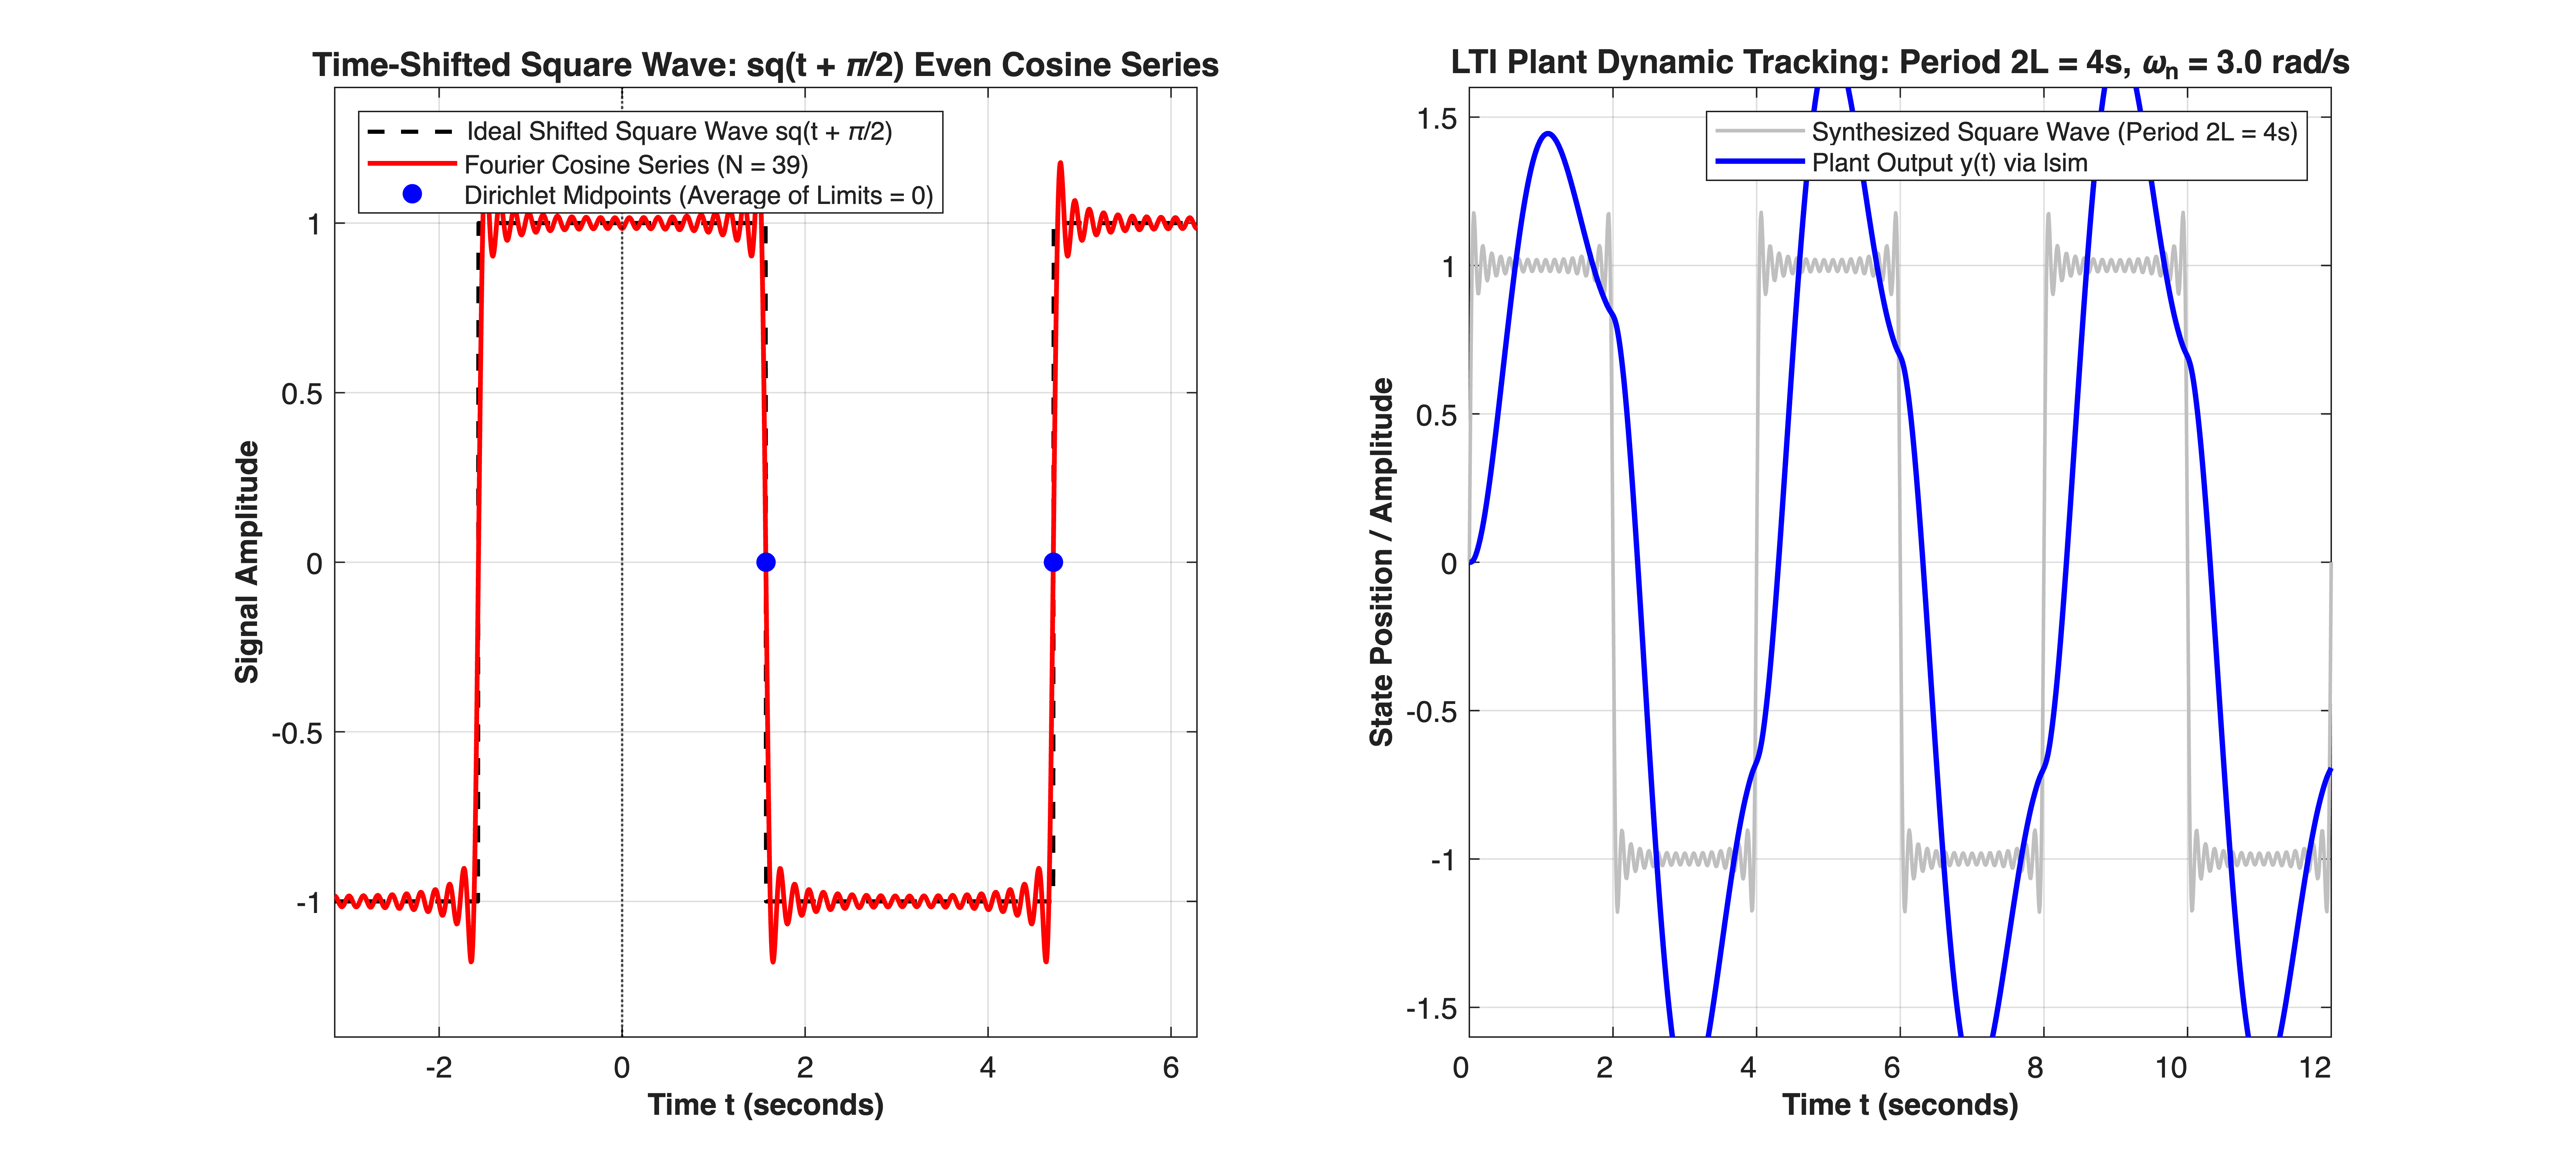

In [5]:


figure('Color', [1 1 1], 'Position', [100, 100, 1150, 520]);


% Subplot 1: Time-Shifted Fourier Waveform and Midpoint Convergence
subplot(1, 2, 1);
hold on; grid on; box on;


% Ideal piecewise shifted square wave
sq_shifted_ideal = square(t_eval + pi/2);
plot(t_eval, sq_shifted_ideal, 'k--', 'LineWidth', 1.4, ...
     'DisplayName', 'Ideal Shifted Square Wave sq(t + \pi/2)');
plot(t_eval, sq_shifted_synth, 'r-', 'LineWidth', 1.6, ...
     'DisplayName', sprintf('Fourier Cosine Series (N = %d)', N_harmonics));


% Mark Dirichlet convergence points at discontinuities t = pi/2 and t = 3*pi/2
plot([pi/2, 3*pi/2], [0, 0], 'bo', 'MarkerFaceColor', 'b', 'MarkerSize', 6, ...
     'DisplayName', 'Dirichlet Midpoints (Average of Limits = 0)');


xline(0, 'k:', 'LineWidth', 0.8, 'HandleVisibility', 'off');
xlabel('Time t (seconds)', 'FontSize', 10, 'FontWeight', 'bold');
ylabel('Signal Amplitude', 'FontSize', 10, 'FontWeight', 'bold');
title('Time-Shifted Square Wave: sq(t + \pi/2) Even Cosine Series', ...
      'FontSize', 11, 'FontWeight', 'bold');
legend('Location', 'northwest', 'FontSize', 8.5);
xlim([-pi, 2 * pi]);
ylim([-1.4, 1.4]);


%% =========================================================================
%% Part 2: Arbitrary Period 2L = 4 Driving an LTI Plant (Sections [4] & MBD)
%% =========================================================================
% System with Period 2L = 4 (L = 2, w0 = pi/2 rad/s)
L_period = 2.0;
w0_scaled = pi / L_period; % w0 = pi/2 ~ 1.5708 rad/s


t_scaled = linspace(0, 12, 1200);
u_scaled_input = zeros(size(t_scaled));


for k = 0:15
    n = 2 * k + 1;
    bn = 4 / (n * pi);
    u_scaled_input = u_scaled_input + bn * sin(n * w0_scaled * t_scaled);
end


% Construct 2nd-order LTI plant via Control System Toolbox:
% G(s) = wn^2 / (s^2 + 2*zeta*wn*s + wn^2)
wn = 3.0;      % Natural frequency in rad/s
zeta = 0.25;   % Light damping ratio
G_plant = tf(wn^2, [1, 2 * zeta * wn, wn^2]);


% Simulate response using Control System Toolbox lsim
[y_plant_out, ~] = lsim(G_plant, u_scaled_input, t_scaled);


% Subplot 2: Dynamic Plant Response to Arbitrary Period Drive
subplot(1, 2, 2);
hold on; grid on; box on;


plot(t_scaled, u_scaled_input, 'Color', [0.75 0.75 0.75], 'LineWidth', 1.2, ...
     'DisplayName', 'Synthesized Square Wave (Period 2L = 4s)');
plot(t_scaled, y_plant_out, 'b-', 'LineWidth', 1.8, ...
     'DisplayName', 'Plant Output y(t) via lsim');


xlabel('Time t (seconds)', 'FontSize', 10, 'FontWeight', 'bold');
ylabel('State Position / Amplitude', 'FontSize', 10, 'FontWeight', 'bold');
title(sprintf('LTI Plant Dynamic Tracking: Period 2L = 4s, \\omega_n = %.1f rad/s', wn), ...
      'FontSize', 11, 'FontWeight', 'bold');
legend('Location', 'northeast', 'FontSize', 8.5);
xlim([0, 12]);
ylim([-1.6, 1.6]);